# Next Word Prediction Model using LSTM

Dataset: [Next Word Prediction (Kaggle)](https://www.kaggle.com/datasets/ronikdedhia/next-word-prediction)

## Download Dataset

In [1]:
import kagglehub

path = kagglehub.dataset_download("ronikdedhia/next-word-prediction")

print("Path to dataset files:", path)

C:\Users\ZOHAIB~1\AppData\Local\Temp\claude\785e7a59becc4091\eadcb306-6683-4e37-a907-c3317fb63f5f\scratchpad\extra\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: C:\Users\Zohaib Ali\.cache\kagglehub\datasets\ronikdedhia\next-word-prediction\versions\1


## Load Text

In [2]:
import os

txt_path = os.path.join(path, os.listdir(path)[0])

In [3]:
with open(txt_path, "r", encoding="charmap") as file:
    text = file.read()

## Text Cleaning

In [4]:
text = text.lower()

In [5]:
import re

matches = re.findall(r"[a-z\s]", text)
text = "".join(matches).strip()

## Lemmatization

In [6]:
import nltk
from nltk.stem import WordNetLemmatizer

nltk.download("wordnet")
lema = WordNetLemmatizer()

lem_text = " ".join([lema.lemmatize(word) for word in text.split()])

[nltk_data] Downloading package wordnet to C:\Users\Zohaib
[nltk_data]     Ali\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [7]:
text_len = len(text)
lemtextlen = len(lem_text)

print(f"length of simple text = {text_len}")
print(f"length of simple lem text = {lemtextlen}")

length of simple text = 557883
length of simple lem text = 547918


## Tokenization

In [8]:
import numpy as np
import tensorflow
from tensorflow import keras
from tensorflow.keras.preprocessing.text import Tokenizer
from nltk.tokenize import sent_tokenize

tok = Tokenizer()

In [9]:
nltk.download("punkt_tab")
text = sent_tokenize(lem_text)

print("Number of sentences:", len(text))

[nltk_data] Downloading package punkt_tab to C:\Users\Zohaib
[nltk_data]     Ali\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


Number of sentences: 1


In [10]:
tok.fit_on_texts(text)
seq = tok.texts_to_sequences(text)
tok_word_seq = tok.word_index

print("Vocabulary size:", len(tok_word_seq))

Vocabulary size: 7820


## Create Input Sequences

In [11]:
data = []
limit = 5000

for s in seq:
    limited_s = s[:limit]
    for i in range(len(limited_s) - 2):
        data.append(limited_s[0:i + 3])

print("Total sequences:", len(data))
print(data[:5])

Total sequences: 4998
[[140, 347, 1], [140, 347, 1, 381], [140, 347, 1, 381, 5], [140, 347, 1, 381, 5, 127], [140, 347, 1, 381, 5, 127, 32]]


In [12]:
x = []
y = []

for r in data:
    x.append(r[:-1])
    y.append(r[-1])

## Padding

In [13]:
from tensorflow.keras.utils import pad_sequences

maxlen = 251
x = pad_sequences(x, maxlen=maxlen, padding="post")
x = x.reshape(len(x), maxlen, 1)
y = np.array(y).reshape(-1, 1)

print("x shape:", x.shape)
print("y shape:", y.shape)

x shape: (4998, 251, 1)
y shape: (4998, 1)


## Train Test Split

In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.23, random_state=42)

print(X_train.shape, X_test.shape)

(3848, 251, 1) (1150, 251, 1)


## Build LSTM Model

In [15]:
from tensorflow.keras import layers

vocab_size = len(tok_word_seq) + 1

model = keras.Sequential([
    layers.Input(shape=(maxlen, 1)),
    layers.LSTM(512, return_sequences=True),
    layers.LSTM(256),
    layers.Dense(vocab_size, activation="softmax"),
])

model.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 251, 512)       │     1,052,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 256)            │       787,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 7821)           │     2,009,997 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,850,125 (14.69 MB)

 Trainable params: 3,850,125 (14.69 MB)

 Non-trainable params: 0 (0.00 B)

## Train Model

In [16]:
history = model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=5, batch_size=64)

Epoch 1/5
 1/61 ━━━━━━━━━━━━━━━━━━━━ 8:37 9s/step - accuracy: 0.0000e+00 - loss: 8.9737
 2/61 ━━━━━━━━━━━━━━━━━━━━ 4:06 4s/step - accuracy: 0.0000e+00 - loss: 8.9446
 3/61 ━━━━━━━━━━━━━━━━━━━━ 4:08 4s/step - accuracy: 0.0052 - loss: 8.9186    
 4/61 ━━━━━━━━━━━━━━━━━━━━ 3:59 4s/step - accuracy: 0.0156 - loss: 8.8754
 5/61 ━━━━━━━━━━━━━━━━━━━━ 3:54 4s/step - accuracy: 0.0156 - loss: 8.8223
 6/61 ━━━━━━━━━━━━━━━━━━━━ 3:56 4s/step - accuracy: 0.0208 - loss: 8.7883
 7/61 ━━━━━━━━━━━━━━━━━━━━ 3:53 4s/step - accuracy: 0.0223 - loss: 8.7246
 8/61 ━━━━━━━━━━━━━━━━━━━━ 3:49 4s/step - accuracy: 0.0254 - loss: 8.6677
 9/61 ━━━━━━━━━━━━━━━━━━━━ 3:43 4s/step - accuracy: 0.0260 - loss: 8.5889
10/61 ━━━━━━━━━━━━━━━━━━━━ 3:40 4s/step - accuracy: 0.0281 - loss: 8.4846
11/61 ━━━━━━━━━━━━━━━━━━━━ 3:37 4s/step - accuracy: 0.0256 - loss: 8.4123
12/61 ━━━━━━━━━━━━━━━━━━━━ 3:34 4s/step - accuracy: 0.0247 - loss: 8.3658
13/61 ━━━━━━━━━━━━━━━━━━━━ 3:33 4s/step - accuracy: 0.0240 - loss: 8.2846
14/61 ━━━━━━━━━━

## Training Results

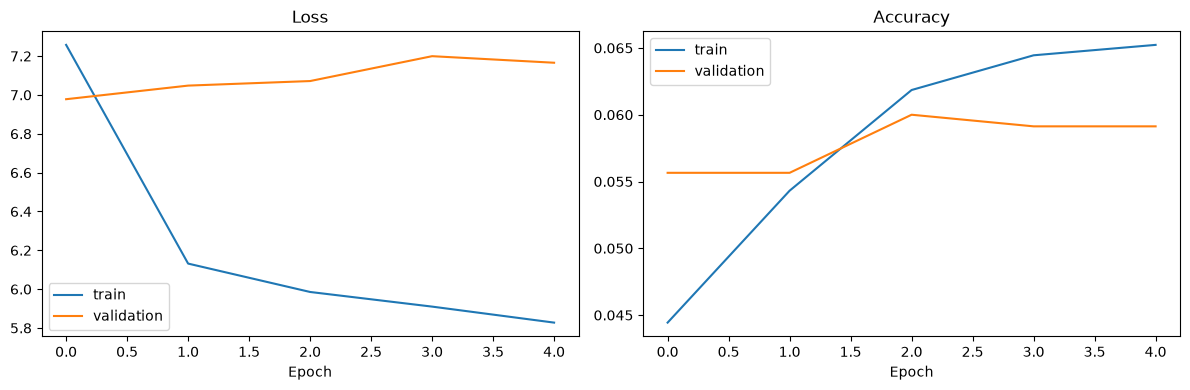

Test loss    : 7.1657
Test accuracy: 0.0591


In [17]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(history.history["loss"], label="train")
ax[0].plot(history.history["val_loss"], label="validation")
ax[0].set_title("Loss")
ax[0].set_xlabel("Epoch")
ax[0].legend()

ax[1].plot(history.history["accuracy"], label="train")
ax[1].plot(history.history["val_accuracy"], label="validation")
ax[1].set_title("Accuracy")
ax[1].set_xlabel("Epoch")
ax[1].legend()

plt.tight_layout()
plt.show()

loss, acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test loss    : {loss:.4f}")
print(f"Test accuracy: {acc:.4f}")

## Next Word Prediction Function

In [18]:
index_word = tok.index_word


def prepare_input(sentence):
    sentence = sentence.lower()
    sentence = "".join(re.findall(r"[a-z\s]", sentence)).strip()
    sentence = " ".join([lema.lemmatize(word) for word in sentence.split()])
    tokens = tok.texts_to_sequences([sentence])[0]
    padded = pad_sequences([tokens], maxlen=maxlen, padding="post")
    return padded.reshape(1, maxlen, 1)


def predict_next_word(sentence):
    probs = model.predict(prepare_input(sentence), verbose=0)[0]
    return index_word.get(int(np.argmax(probs)), "")


def predict_top_words(sentence, top_k=5):
    probs = model.predict(prepare_input(sentence), verbose=0)[0]
    top = np.argsort(probs)[::-1][:top_k]
    return [(index_word.get(int(i), ""), float(probs[i])) for i in top]


def generate_text(sentence, n_words=5):
    for _ in range(n_words):
        sentence = sentence + " " + predict_next_word(sentence)
    return sentence

## Test with Different Input Sentences

In [19]:
test_sentences = [
    "project gutenberg the",
    "the adventure of sherlock",
    "this ebook is for the use of",
    "you may copy it give it",
    "arthur conan",
    "a scandal in",
    "to sherlock holmes she is always the",
    "i had seen little of",
]

for s in test_sentences:
    top = predict_top_words(s, top_k=3)
    print(f"Input : {s}")
    print(f"Next  : {top[0][0]}")
    print("Top 3 : " + ", ".join(f"{w} ({p:.1%})" for w, p in top))
    print()

Input : project gutenberg the
Next  : the
Top 3 : the (6.5%), a (2.1%), wa (1.7%)

Input : the adventure of sherlock
Next  : the
Top 3 : the (6.5%), a (2.1%), wa (1.7%)

Input : this ebook is for the use of
Next  : the
Top 3 : the (6.5%), a (2.1%), wa (1.7%)

Input : you may copy it give it
Next  : the
Top 3 : the (6.5%), a (2.1%), wa (1.7%)

Input : arthur conan
Next  : the
Top 3 : the (6.5%), a (2.1%), wa (1.7%)

Input : a scandal in
Next  : the
Top 3 : the (6.5%), a (2.1%), wa (1.7%)

Input : to sherlock holmes she is always the
Next  : the
Top 3 : the (6.5%), a (2.1%), wa (1.7%)

Input : i had seen little of
Next  : the
Top 3 : the (6.5%), a (2.1%), wa (1.7%)



## Text Generation

In [20]:
for seed in ["project gutenberg", "the adventure of", "sherlock holmes"]:
    print(generate_text(seed, n_words=6))

project gutenberg the the the the the the
the adventure of the the the the the the
sherlock holmes the the the the the the
